In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score,
                             completeness_score, v_measure_score)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
np.random.seed(42)

In [33]:
wine = load_wine()
X = wine.data
y_true = wine.target           # 0,1,2 — сорт вина
feature_names = wine.feature_names

print("Размерность:", X.shape)
print("Классы:", np.bincount(y_true))
print("Признаки:", feature_names)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Объяснённая дисперсия PCA(2):", pca.explained_variance_ratio_.sum())

Размерность: (178, 13)
Классы: [59 71 48]
Признаки: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Объяснённая дисперсия PCA(2): 0.5540633835693526


In [34]:
methods = ['single', 'complete', 'average', 'ward']

metrics_map = {
    'single':   ['euclidean', 'cityblock', 'cosine', 'correlation', 'chebyshev'],
    'complete': ['euclidean', 'cityblock', 'cosine', 'correlation', 'chebyshev'],
    'average':  ['euclidean', 'cityblock', 'cosine', 'correlation', 'chebyshev'],
    'ward':     ['euclidean'],
}

K_LIST = [2, 3, 4]

results = []

for method in methods:
    for metric in metrics_map[method]:
        Z = linkage(X_scaled, method=method, metric=metric)

        c, _ = cophenet(Z, pdist(X_scaled, metric=metric))

        for k in K_LIST:
            labels = fcluster(Z, t=k, criterion='maxclust')
            n_clusters = len(np.unique(labels))
            if n_clusters < 2:
                continue

            sil  = silhouette_score(X_scaled, labels)
            ch   = calinski_harabasz_score(X_scaled, labels)
            db   = davies_bouldin_score(X_scaled, labels)
            ari  = adjusted_rand_score(y_true, labels)
            nmi  = normalized_mutual_info_score(y_true, labels)
            hom  = homogeneity_score(y_true, labels)
            com  = completeness_score(y_true, labels)
            vms  = v_measure_score(y_true, labels)

            results.append({
                'method': method, 'metric': metric, 'k': k,
                'cophenet': c,
                'silhouette': sil, 'calinski': ch, 'davies': db,
                'ARI': ari, 'NMI': nmi, 'homog': hom,
                'compl': com, 'V-measure': vms
            })

df_res = pd.DataFrame(results)
print(f"Всего экспериментов: {len(df_res)}")
df_res.head(10)

Всего экспериментов: 48


,method,metric,k,cophenet,silhouette,calinski,davies,ARI,NMI,homog,compl,V-measure
0,single,euclidean,2,0.543623,0.222451,5.744292,1.051416,-0.005179,0.026817,0.014464,0.183668,0.026817
1,single,euclidean,3,0.543623,0.182738,4.061665,0.910518,-0.006814,0.034895,0.019378,0.175160,0.034895
2,single,euclidean,4,0.543623,0.181078,3.765965,0.819313,-0.008336,0.042606,0.024338,0.170828,0.042606
3,single,cityblock,2,0.403933,0.298862,2.957871,0.564836,-0.001963,0.009257,0.004776,0.149437,0.009257
4,single,cityblock,3,0.403933,0.197952,2.828435,0.584997,-0.003819,0.018042,0.009598,0.150204,0.018042
5,single,cityblock,4,0.403933,0.074994,2.345955,0.705091,-0.005567,0.026400,0.014464,0.150982,0.026400
6,single,cosine,2,0.515940,0.222451,5.744292,1.051416,-0.005179,0.026817,0.014464,0.183668,0.026817
7,single,cosine,3,0.515940,-0.114282,3.123793,1.253696,-0.006814,0.034895,0.019378,0.175160,0.034895
8,single,cosine,4,0.515940,-0.118332,2.553713,1.144349,-0.008336,0.042606,0.024338,0.170828,0.042606
9,single,correlation,2,0.400144,-0.082584,0.661000,1.193313,-0.001963,0.009257,0.004776,0.149437,0.009257


In [35]:
pivot = df_res[df_res['k'] == 3].copy()
pivot = pivot.set_index(['method', 'metric'])

show_cols = ['cophenet', 'silhouette', 'calinski', 'davies',
             'ARI', 'NMI', 'V-measure']
print("=== Результаты при k = 3 (истинное число классов) ===")
print(pivot[show_cols].round(4).to_string())

=== Результаты при k = 3 (истинное число классов) ===
                      cophenet  silhouette  calinski  davies     ARI     NMI  V-measure
method   metric                                                                        
single   euclidean      0.5436      0.1827    4.0617  0.9105 -0.0068  0.0349     0.0349
         cityblock      0.4039      0.1980    2.8284  0.5850 -0.0038  0.0180     0.0180
         cosine         0.5159     -0.1143    3.1238  1.2537 -0.0068  0.0349     0.0349
         correlation    0.4001     -0.0775    3.2118  1.1333 -0.0068  0.0349     0.0349
         chebyshev      0.5336      0.2129    2.6338  0.6155 -0.0038  0.0180     0.0180
complete euclidean      0.5917      0.2038   48.9898  1.8961  0.5771  0.6144     0.6144
         cityblock      0.6376      0.1899   44.0328  1.8747  0.4855  0.6197     0.6197
         cosine         0.7076      0.2443   59.9080  1.5482  0.5972  0.6330     0.6330
         correlation    0.6486      0.1313   37.6317  2.6975  0.30

In [36]:
best_ari = df_res.loc[df_res['ARI'].idxmax()]
best_sil = df_res.loc[df_res['silhouette'].idxmax()]
best_vm  = df_res.loc[df_res['V-measure'].idxmax()]

print("Лучший по ARI:\n", best_ari.to_string(), "\n")
print("Лучший по Silhouette:\n", best_sil.to_string(), "\n")
print("Лучший по V-measure:\n", best_vm.to_string())

Лучший по ARI:
 method            average
metric        correlation
k                       3
cophenet         0.778201
silhouette        0.27017
calinski        65.080372
davies           1.452279
ARI              0.822449
NMI              0.804968
homog            0.809026
compl            0.800952
V-measure        0.804968 

Лучший по Silhouette:
 method           single
metric        cityblock
k                     2
cophenet       0.403933
silhouette     0.298862
calinski       2.957871
davies         0.564836
ARI           -0.001963
NMI            0.009257
homog          0.004776
compl          0.149437
V-measure      0.009257 

Лучший по V-measure:
 method            average
metric        correlation
k                       3
cophenet         0.778201
silhouette        0.27017
calinski        65.080372
davies           1.452279
ARI              0.822449
NMI              0.804968
homog            0.809026
compl            0.800952
V-measure        0.804968


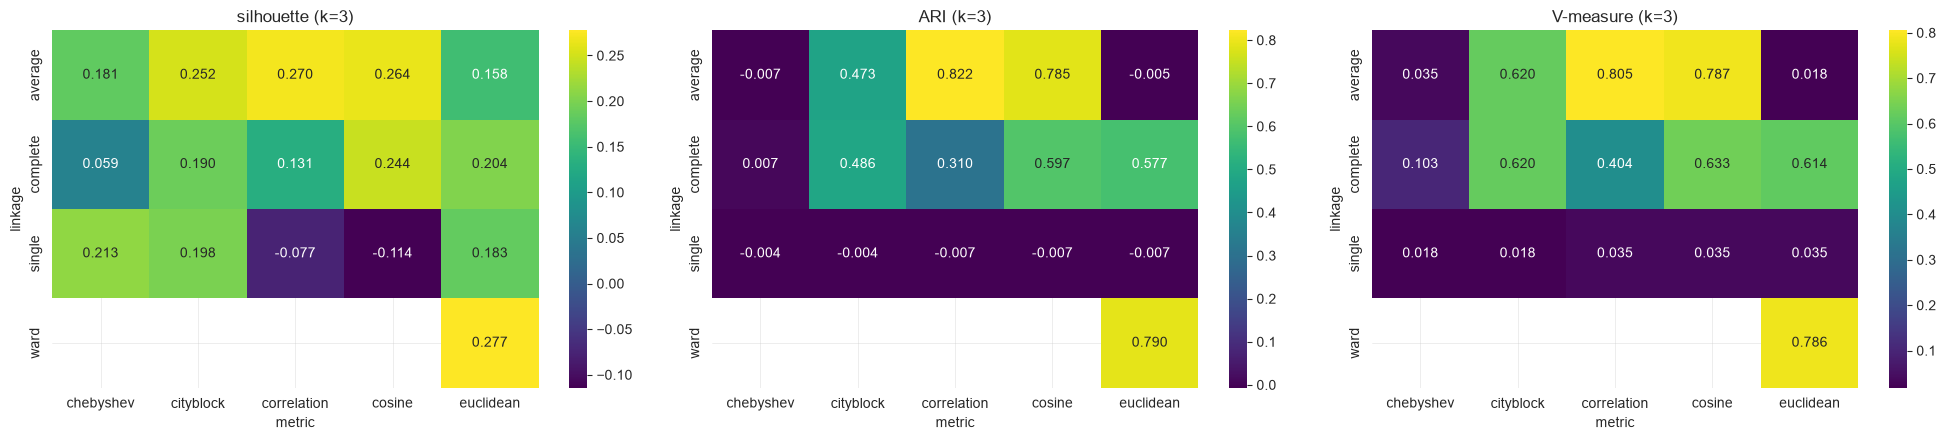

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))

for ax, col in zip(axes, ['silhouette', 'ARI', 'V-measure']):
    hm = pivot[col].unstack()
    sns.heatmap(hm, annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(f"{col} (k=3)")
    ax.set_xlabel("metric")
    ax.set_ylabel("linkage")

plt.tight_layout()
plt.show()

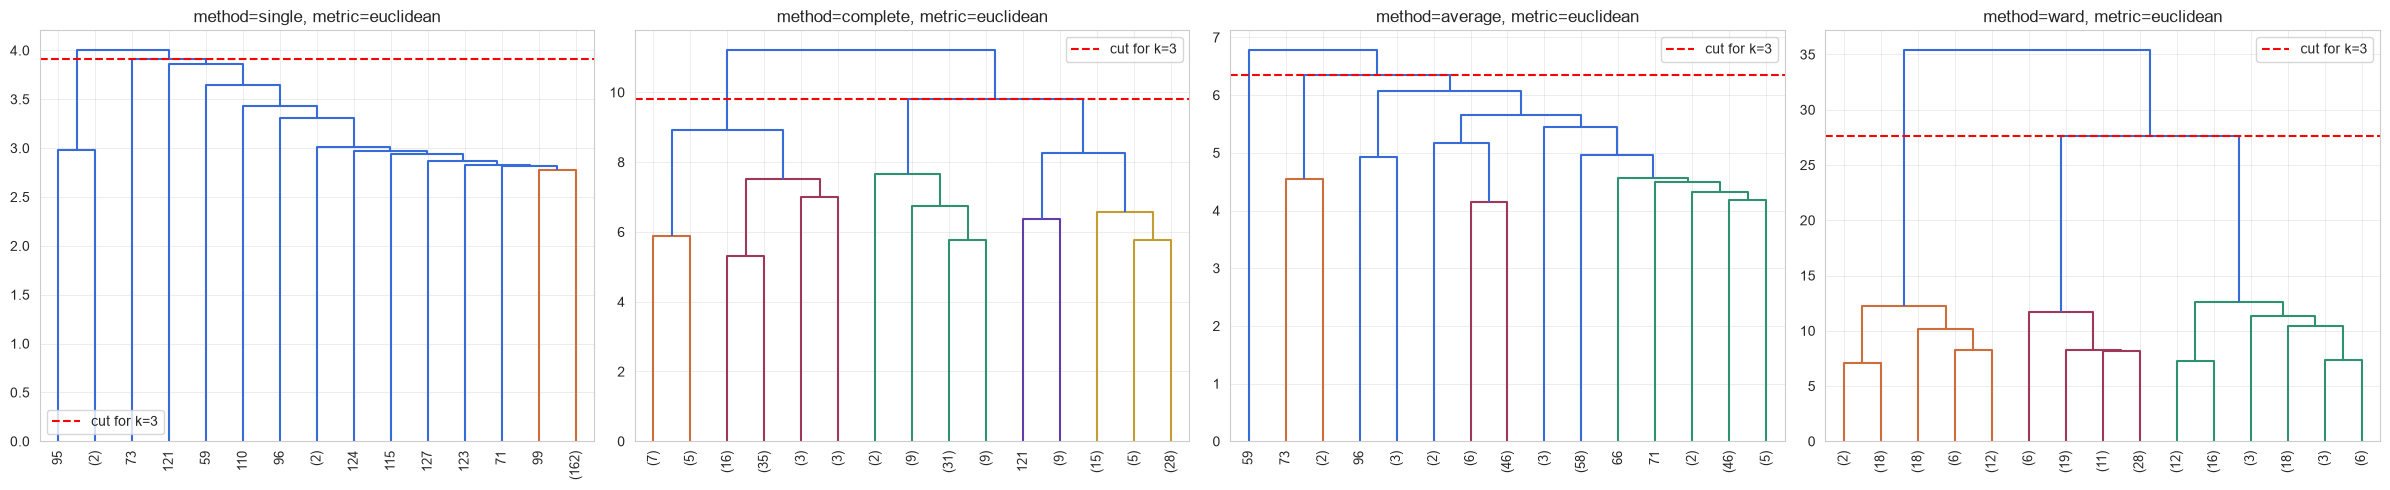

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for ax, method in zip(axes, methods):
    Z = linkage(X_scaled, method=method, metric='euclidean')
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=15,
               leaf_rotation=90, leaf_font_size=9)
    ax.set_title(f"method={method}, metric=euclidean")
    ax.axhline(y=Z[-2, 2], color='red', linestyle='--', label='cut for k=3')
    ax.legend()

plt.tight_layout()
plt.show()

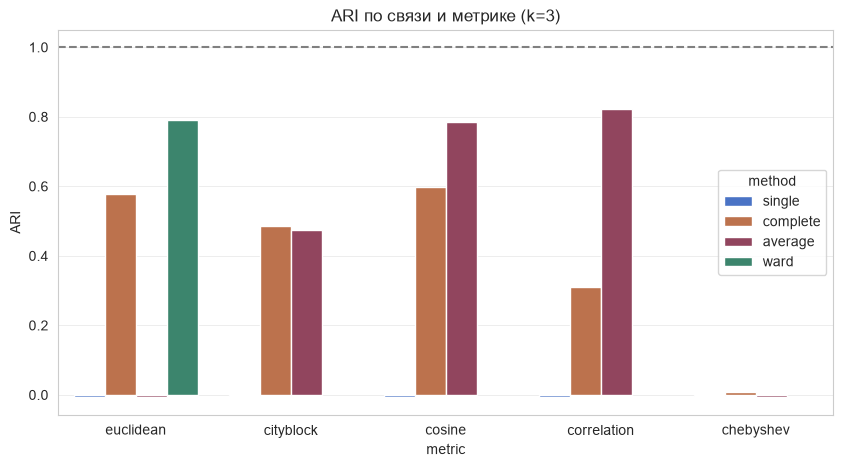

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df_res[df_res['k'] == 3], x='metric', y='ARI',
            hue='method', ax=ax)
ax.set_title("ARI по связи и метрике (k=3)")
ax.axhline(1.0, color='gray', ls='--')
plt.show()

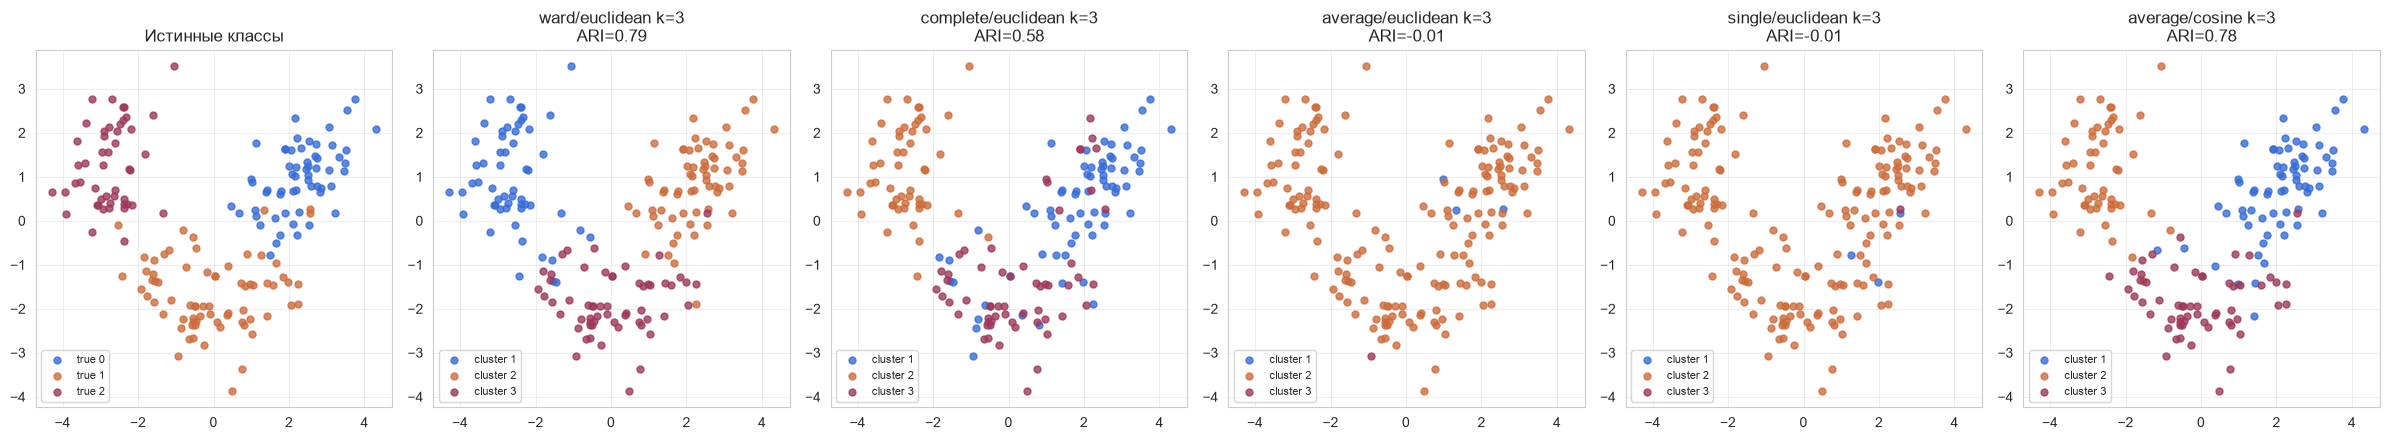

In [41]:
def plot_clusters(labels, title, ax):
    for c in np.unique(labels):
        ax.scatter(X_pca[labels == c, 0], X_pca[labels == c, 1],
                   label=f'cluster {c}', s=25, alpha=0.8)
    ax.set_title(title); ax.legend(fontsize=8)

best_combos = [
    ('ward', 'euclidean', 3),
    ('complete', 'euclidean', 3),
    ('average', 'euclidean', 3),
    ('single', 'euclidean', 3),
    ('average', 'cosine', 3),
]

fig, axes = plt.subplots(1, len(best_combos) + 1,
                         figsize=(24, 4.5))

for c in np.unique(y_true):
    axes[0].scatter(X_pca[y_true == c, 0], X_pca[y_true == c, 1],
                    label=f'true {c}', s=25, alpha=0.8)
axes[0].set_title("Истинные классы"); axes[0].legend(fontsize=8)

for ax, (m, mt, k) in zip(axes[1:], best_combos):
    Z = linkage(X_scaled, method=m, metric=mt)
    lab = fcluster(Z, t=k, criterion='maxclust')
    plot_clusters(lab, f"{m}/{mt} k={k}\nARI={adjusted_rand_score(y_true, lab):.2f}", ax)

plt.tight_layout()
plt.show()

In [42]:
thresholds = [5, 10, 15, 20, 25]
res_thr = []

for method in methods:
    Z = linkage(X_scaled, method=method, metric='euclidean')
    for t in thresholds:
        labels = fcluster(Z, t=t, criterion='distance')
        if len(np.unique(labels)) < 2:
            continue
        res_thr.append({
            'method': method, 'threshold': t,
            'n_clusters': len(np.unique(labels)),
            'silhouette': silhouette_score(X_scaled, labels),
            'ARI': adjusted_rand_score(y_true, labels),
            'V-measure': v_measure_score(y_true, labels),
        })

df_thr = pd.DataFrame(res_thr)
print(df_thr.round(4).to_string(index=False))

  method  threshold  n_clusters  silhouette    ARI  V-measure
complete          5          21      0.1227 0.2881     0.5450
complete         10           2      0.1619 0.2953     0.3539
 average          5           7      0.1925 0.4118     0.5215
    ward          5          28      0.1327 0.1331     0.4534
    ward         10           9      0.1917 0.5105     0.6060
    ward         15           3      0.2774 0.7899     0.7865
    ward         20           3      0.2774 0.7899     0.7865
    ward         25           3      0.2774 0.7899     0.7865
